# YOLOv8 Traffic Sign Detection

This notebook implements YOLOv8n object detection to locate traffic signs in road images and generate bounding boxes. The detected signs will later be classified using our trained Custom CNN.

In [2]:
!pip -q install ultralytics

from ultralytics import YOLO
import torch

print("Ultralytics installed successfully!")
print("GPU available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics installed successfully!
GPU available: True


In [3]:
import torch

print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

GPU available: True
Device: Tesla T4


## GTSRB Dataset and Bounding-Box Preparation

In [4]:
from pathlib import Path
import pandas as pd

DATASET_ROOT = Path(
    "/kaggle/input/gtsrb-german-traffic-sign"
)

print("Dataset exists:", DATASET_ROOT.exists())

if DATASET_ROOT.exists():
    print("Files:", [p.name for p in DATASET_ROOT.iterdir()][:15])
else:
    print("Dataset is not available at this path.")

Dataset exists: False
Dataset is not available at this path.


## Download and Verify the GTSRB Dataset

In [5]:
!pip -q install kagglehub

import kagglehub
from pathlib import Path

dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

DATASET_ROOT = Path(dataset_path)

print("Dataset downloaded successfully!")
print("Dataset location:", DATASET_ROOT)
print("Files:", [p.name for p in DATASET_ROOT.iterdir()])

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/gtsrb-german-traffic-sign
Files: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


## Inspect GTSRB Bounding-Box Annotations

In [6]:
import pandas as pd

train_df = pd.read_csv(DATASET_ROOT / "Train.csv")
test_df = pd.read_csv(DATASET_ROOT / "Test.csv")

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("\nTraining columns:")
print(train_df.columns.tolist())
print("\nFirst training example:")
print(train_df.iloc[0])

print("\nNumber of classes:", train_df["ClassId"].nunique())

Training images: 39209
Testing images: 12630

Training columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

First training example:
Width                                  27
Height                                 26
Roi.X1                                  5
Roi.Y1                                  5
Roi.X2                                 22
Roi.Y2                                 20
ClassId                                20
Path       Train/20/00020_00000_00000.png
Name: 0, dtype: object

Number of classes: 43


## Visual Verification of GTSRB Bounding Boxes

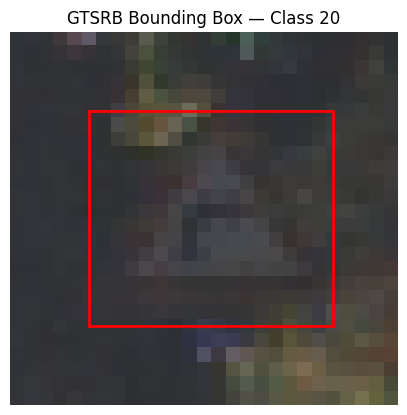

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

row = train_df.iloc[0]
image_path = DATASET_ROOT / row["Path"]
image = Image.open(image_path).convert("RGB")

x1 = int(row["Roi.X1"])
y1 = int(row["Roi.Y1"])
x2 = int(row["Roi.X2"])
y2 = int(row["Roi.Y2"])

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image)

rectangle = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rectangle)
ax.set_title(f"GTSRB Bounding Box — Class {row['ClassId']}")
ax.axis("off")

plt.show()

## Validate GTSRB Bounding-Box Annotations

In [8]:
#to check that every bounding box is inside its image
valid_boxes = (
    (train_df["Roi.X1"] >= 0) &
    (train_df["Roi.Y1"] >= 0) &
    (train_df["Roi.X2"] > train_df["Roi.X1"]) &
    (train_df["Roi.Y2"] > train_df["Roi.Y1"]) &
    (train_df["Roi.X2"] < train_df["Width"]) &
    (train_df["Roi.Y2"] < train_df["Height"])
)

print("Total training images:", len(train_df))
print("Valid bounding boxes:", valid_boxes.sum())
print("Invalid bounding boxes:", (~valid_boxes).sum())

Total training images: 39209
Valid bounding boxes: 39209
Invalid bounding boxes: 0


## Create Group-Aware Training and Validation Splits

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path

train_df["TrackGroup"] = train_df["Path"].apply(
    lambda p: str(Path(p).parent) + "/" +
              Path(p).stem.rsplit("_", 1)[0]
)

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

selected = None

for train_idx, val_idx in splitter.split(
    train_df,
    y=train_df["ClassId"],
    groups=train_df["TrackGroup"]
):
    train_classes = train_df.iloc[train_idx]["ClassId"].nunique()
    val_classes = train_df.iloc[val_idx]["ClassId"].nunique()

    if train_classes == 43 and val_classes == 43:
        selected = (train_idx, val_idx)
        break

if selected is None:
    raise ValueError(
        "No fold contains all 43 classes. "
        "We need to adjust the split."
    )

train_idx, val_idx = selected

yolo_train_df = train_df.iloc[train_idx].copy()
yolo_val_df = train_df.iloc[val_idx].copy()

overlap = (
    set(yolo_train_df["TrackGroup"]) &
    set(yolo_val_df["TrackGroup"])
)
print("Training images:", len(yolo_train_df))
print("Validation images:", len(yolo_val_df))
print("Shared track groups:", len(overlap))
print("Training classes:", yolo_train_df["ClassId"].nunique())
print("Validation classes:", yolo_val_df["ClassId"].nunique())
assert len(overlap) == 0
assert yolo_train_df["ClassId"].nunique() == 43
assert yolo_val_df["ClassId"].nunique() == 43

Training images: 31379
Validation images: 7830
Shared track groups: 0
Training classes: 43
Validation classes: 43


## Prepare YOLO Detection Dataset

In [11]:
from pathlib import Path
from PIL import Image
import shutil

YOLO_ROOT = Path("/content/gtsrb_yolo")

def prepare_yolo_split(df, split_name):
    image_dir = YOLO_ROOT / "images" / split_name
    label_dir = YOLO_ROOT / "labels" / split_name
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for i, (_, row) in enumerate(df.iterrows()):
        source = DATASET_ROOT / row["Path"]

        if not source.is_file():
            raise FileNotFoundError(source)

        filename = f"{split_name}_{i:06d}"
        destination = image_dir / f"{filename}.png"

        with Image.open(source) as img:
            width, height = img.size

        if width != int(row["Width"]) or height != int(row["Height"]):
            raise ValueError(f"Image dimensions mismatch: {source}")

        shutil.copy2(source, destination)

        #convert bounding box to YOLO format
        x1 = float(row["Roi.X1"])
        y1 = float(row["Roi.Y1"])
        x2 = float(row["Roi.X2"])
        y2 = float(row["Roi.Y2"])

        x_center = ((x1 + x2) / 2) / width
        y_center = ((y1 + y2) / 2) / height
        box_width = (x2 - x1) / width
        box_height = (y2 - y1) / height

        class_id = int(row["ClassId"])

        label = (
            f"{class_id} "
            f"{x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}\n"
        )

        (label_dir / f"{filename}.txt").write_text(label)

    print(f"{split_name}: {len(df)} images prepared")


prepare_yolo_split(yolo_train_df, "train")
prepare_yolo_split(yolo_val_df, "val")
print("YOLO detection dataset ready!")

train: 31379 images prepared
val: 7830 images prepared
YOLO detection dataset ready!


## Create and Verify YOLO Dataset Configuration

In [12]:
import yaml
from pathlib import Path

YOLO_ROOT = Path("/content/gtsrb_yolo")
class_names = {i: f"Traffic Sign {i}" for i in range(43)}

data_config = {
    "path": str(YOLO_ROOT),
    "train": "images/train",
    "val": "images/val",
    "nc": 43,
    "names": class_names
}

yaml_path = YOLO_ROOT / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)
print("Configuration created:", yaml_path)

for split in ["train", "val"]:
    images = list((YOLO_ROOT / "images" / split).glob("*.png"))
    labels = list((YOLO_ROOT / "labels" / split).glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} labels")
    assert len(images) == len(labels)

assert len(class_names) == 43

print("YOLO configuration verified!")

Configuration created: /content/gtsrb_yolo/data.yaml
train: 31379 images, 31379 labels
val: 7830 images, 7830 labels
YOLO configuration verified!


## Initialize YOLOv8n Object Detection Model

In [13]:
from ultralytics import YOLO
import torch

model = YOLO("yolov8n.pt")

print("YOLOv8n detection model loaded!")
print("Task:", model.task)
print("GPU available:", torch.cuda.is_available())

assert model.task == "detect"

YOLOv8n detection model loaded!
Task: detect
GPU available: True


## Train YOLOv8n Object Detection Model

In [15]:
from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "Please enable the GPU."
model = YOLO("yolov8n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=25,
    imgsz=320,
    batch=16,
    device=0,
    patience=5,
    optimizer="Adam",
    lr0=0.001,
    seed=42,
    project="/content/drive/MyDrive/ARTI502_Project/yolo_runs",
    name="gtsrb_detection",
    exist_ok=True,
    plots=True
)

print("YOLO training completed!")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsrb_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gtsrb_detection, nbs=64, nms=None, opset=None, optimize=Fa

## Load Best YOLOv8n Detection Model

In [16]:
from ultralytics import YOLO
from pathlib import Path

best_model_path = Path(
    "/content/drive/MyDrive/ARTI502_Project/"
    "yolo_runs/gtsrb_detection/weights/best.pt"
)

assert best_model_path.exists(), "Best model not found."
detector = YOLO(str(best_model_path))
print("Best YOLO detection model loaded!")
print("Task:", detector.task)

assert detector.task == "detect"

Best YOLO detection model loaded!
Task: detect


## Evaluate Detection Performance

In [17]:
metrics = detector.val(
    data=str(yaml_path),
    split="val",
    imgsz=320,
    batch=16,
    device=0,
    plots=True
)



print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@50:", metrics.box.map50)
print("mAP@50–95:", metrics.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,142,913 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 319.1±208.3 MB/s, size: 6.8 KB)
val: Scanning /content/gtsrb_yolo/labels/val.cache... 7830 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7830/7830 2.3Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 490/490 10.6it/s 46.3s
                   all       7830       7830      0.896      0.954      0.932      0.878
        Traffic Sign 0         30         30      0.761          1      0.995      0.928
        Traffic Sign 1        450        450      0.999      0.991      0.995      0.935
        Traffic Sign 2        420        420      0.997      0.995      0.995      0.932
        Traffic Sign 3        300        300      0.997          1      0.995      0.926
        Traffic Sign 4        390        39

## Visualize Predicted Bounding Boxes

val_000000.png Detected boxes: 1


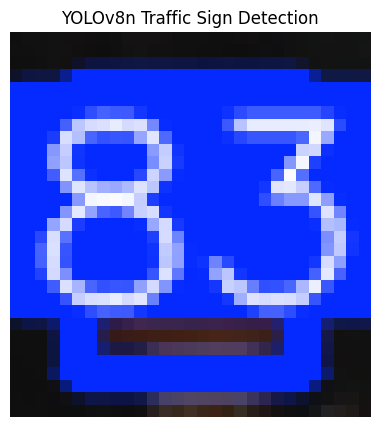

val_000001.png Detected boxes: 1


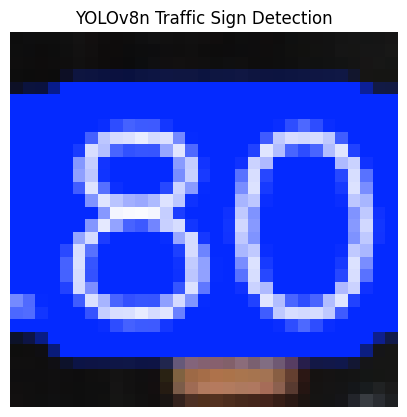

val_000002.png Detected boxes: 1


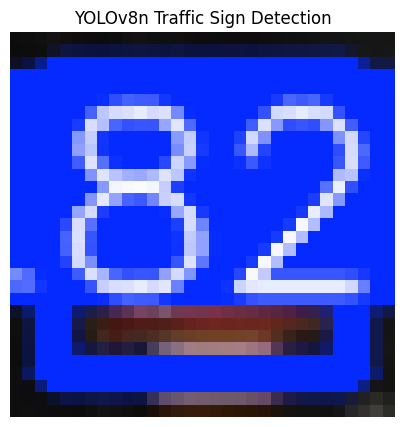

val_000003.png Detected boxes: 1


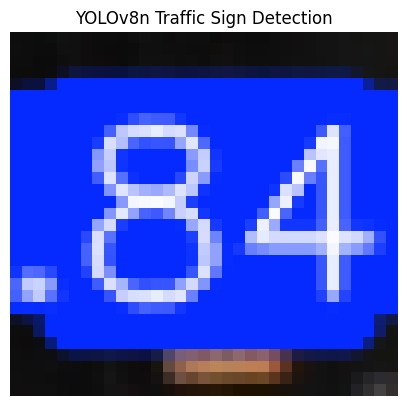

val_000004.png Detected boxes: 1


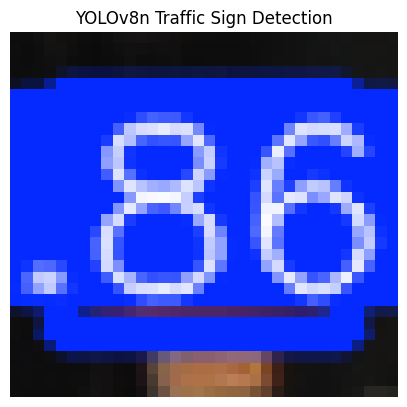

In [23]:
import matplotlib.pyplot as plt
from PIL import Image

sample_images = sorted(
    (YOLO_ROOT / "images" / "val").glob("*.png")
)[:5]

assert sample_images, "No validation images found."

for image_path in sample_images:
    predictions = detector.predict(
        source=str(image_path),
        imgsz=320,
        conf=0.25,
        verbose=False
    )

    print(image_path.name, "Detected boxes:", len(predictions[0].boxes))

    annotated_image = predictions[0].plot()
    plt.figure(figsize=(5, 5))
    plt.imshow(annotated_image[:, :, ::-1])
    plt.title("YOLOv8n Traffic Sign Detection")
    plt.axis("off")
    plt.show()

In [24]:
result = detector.predict(
    source=str(sample_images[0]),
    imgsz=320,
    conf=0.25,
    verbose=False
)[0]

print("Detected boxes:", len(result.boxes))
print("Coordinates:", result.boxes.xyxy.cpu().numpy())
print("Classes:", result.boxes.cls.cpu().numpy())
print("Confidence:", result.boxes.conf.cpu().numpy())

Detected boxes: 1
Coordinates: [[     5.2863      4.6187      23.504      27.011]]
Classes: [         20]
Confidence: [    0.82704]


## Integrate YOLOv8n Detection with Custom CNN Classification

In [39]:
from google.colab import files

uploaded = files.upload()

Saving CNN_Combined_Final.keras to CNN_Combined_Final.keras


In [40]:
from pathlib import Path

cnn_path = Path("/content/CNN_Combined_Final.keras")

print("CNN exists:", cnn_path.exists())

CNN exists: True


In [41]:
import tensorflow as tf

cnn = tf.keras.models.load_model(
    "/content/CNN_Combined_Final.keras",
    compile=False
)

print("CNN loaded successfully!")
print("Input shape:", cnn.input_shape)
print("Output shape:", cnn.output_shape)

CNN loaded successfully!
Input shape: (None, 32, 32, 3)
Output shape: (None, 43)


In [46]:

def detect_and_classify(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError("Cannot read image.")

    results = detector.predict(
        source=image,
        imgsz=320,
        conf=0.25,
        verbose=False
    )

    h, w = image.shape[:2]

    for box in results[0].boxes:
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].cpu().numpy()
        )

        x1, x2 = max(0, x1), min(w, x2)
        y1, y2 = max(0, y1), min(h, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        crop = image[y1:y2, x1:x2]
        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        crop = cv2.resize(crop, (32, 32))
        crop = crop.astype("float32") / 255.0
        crop = np.expand_dims(crop, axis=0)

        probabilities = cnn.predict(crop, verbose=0)[0]

        class_id = int(np.argmax(probabilities))
        confidence = float(np.max(probabilities))

        print(f"Predicted class: {class_id}")
        print(f"CNN confidence: {confidence:.2%}")

        label = f"Class {class_id}: {confidence:.1%}"

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            label,
            (x1, max(12, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.35,
            (0, 255, 0),
            1,
            cv2.LINE_AA
        )

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


## Test the Integrated YOLO + CNN System

Predicted class: 20
CNN confidence: 85.37%


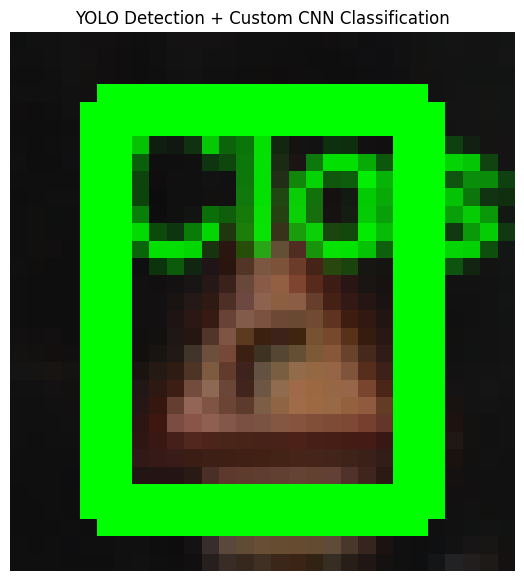

In [47]:
import matplotlib.pyplot as plt

test_image = sorted(
    (YOLO_ROOT / "images" / "val").glob("*.png")
)[0]

output_image = detect_and_classify(test_image)
plt.figure(figsize=(7, 7))
plt.imshow(output_image)
plt.title("YOLO Detection + Custom CNN Classification")
plt.axis("off")
plt.show()

Number of test images: 10

--- Image 1: val_000000.png ---
Predicted class: 20
CNN confidence: 85.37%


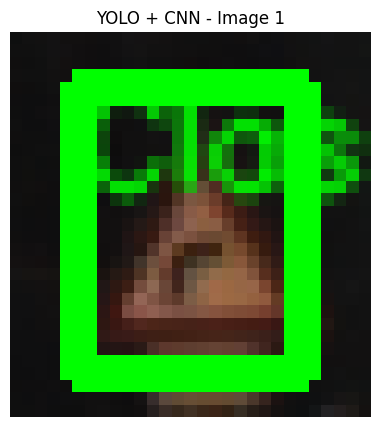


--- Image 2: val_000001.png ---
Predicted class: 20
CNN confidence: 77.07%


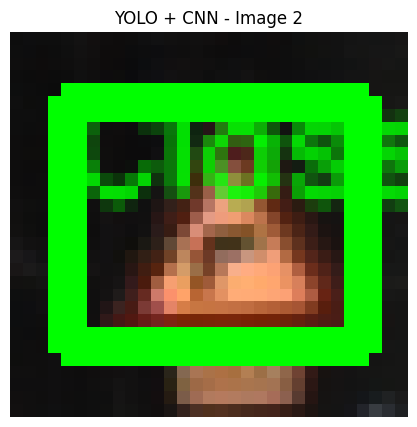


--- Image 3: val_000002.png ---
Predicted class: 20
CNN confidence: 98.06%


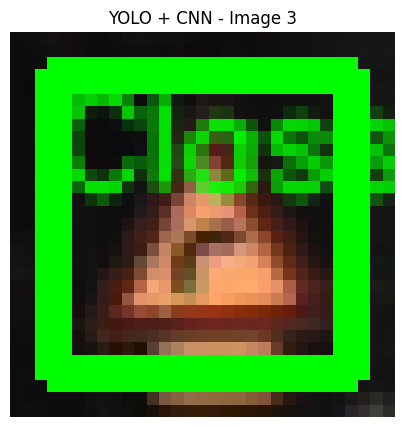


--- Image 4: val_000003.png ---
Predicted class: 20
CNN confidence: 99.27%


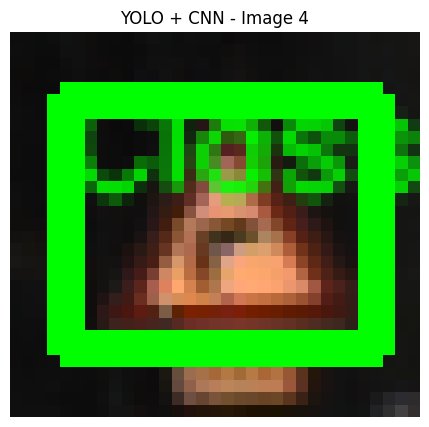


--- Image 5: val_000004.png ---
Predicted class: 20
CNN confidence: 83.02%


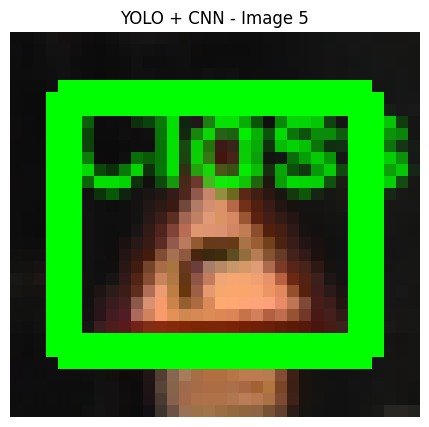


--- Image 6: val_000005.png ---
Predicted class: 20
CNN confidence: 98.60%


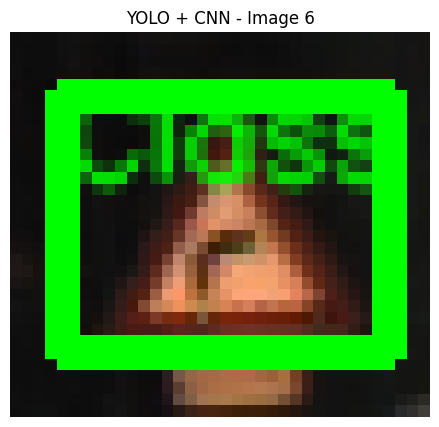


--- Image 7: val_000006.png ---
Predicted class: 20
CNN confidence: 99.19%


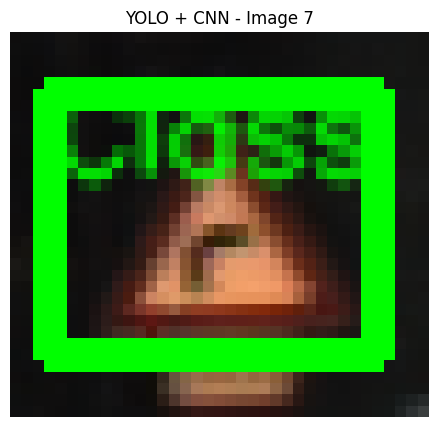


--- Image 8: val_000007.png ---
Predicted class: 20
CNN confidence: 99.06%


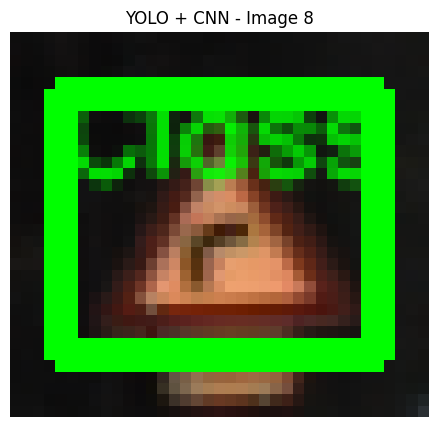


--- Image 9: val_000008.png ---
Predicted class: 20
CNN confidence: 96.14%


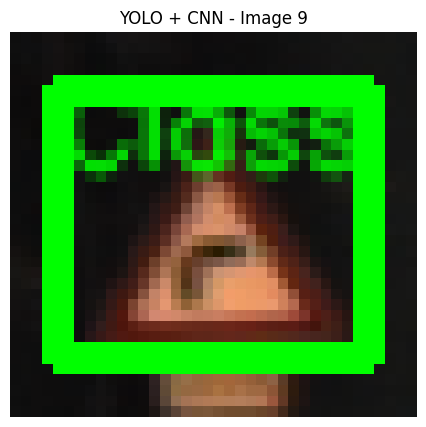


--- Image 10: val_000009.png ---
Predicted class: 20
CNN confidence: 92.91%


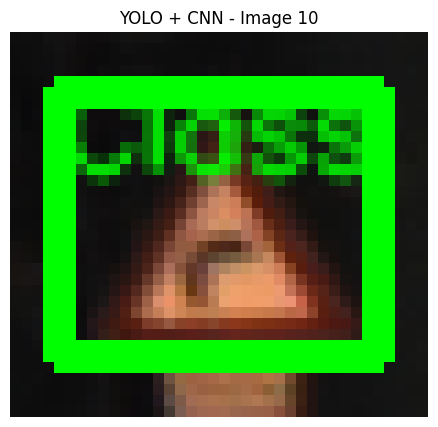

In [48]:
import matplotlib.pyplot as plt
from pathlib import Path

test_images = sorted(
    (YOLO_ROOT / "images" / "val").glob("*.png")
)[:10]

print("Number of test images:", len(test_images))

for i, image_path in enumerate(test_images, start=1):
    print(f"\n--- Image {i}: {image_path.name} ---")

    result_image = detect_and_classify(image_path)

    plt.figure(figsize=(6, 5))
    plt.imshow(result_image)
    plt.title(f"YOLO + CNN - Image {i}")
    plt.axis("off")
    plt.show()


Total validation images: 7830

Testing: val_000000.png
Predicted class: 20
CNN confidence: 85.37%


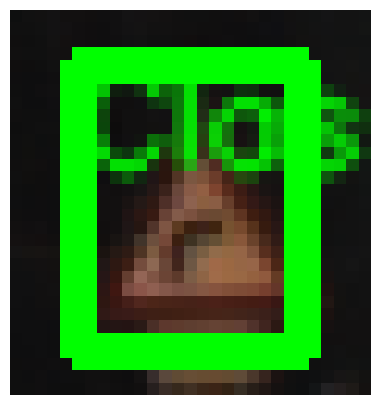


Testing: val_001957.png
Predicted class: 5
CNN confidence: 99.95%


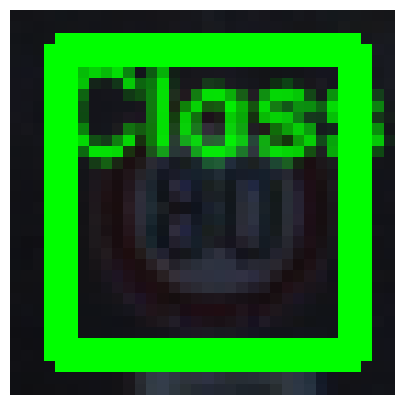


Testing: val_003915.png
Predicted class: 12
CNN confidence: 100.00%


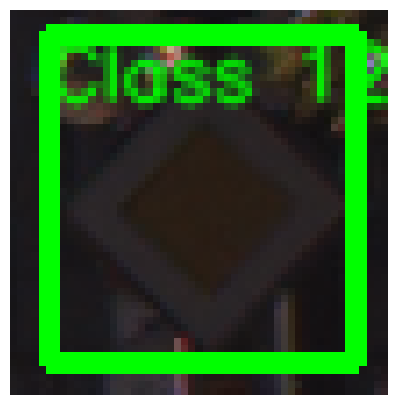


Testing: val_005872.png
Predicted class: 25
CNN confidence: 75.94%


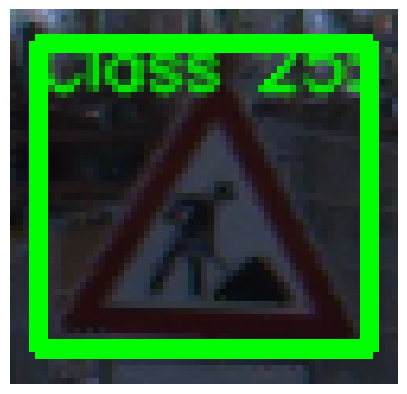


Testing: val_007829.png
Predicted class: 42
CNN confidence: 83.23%


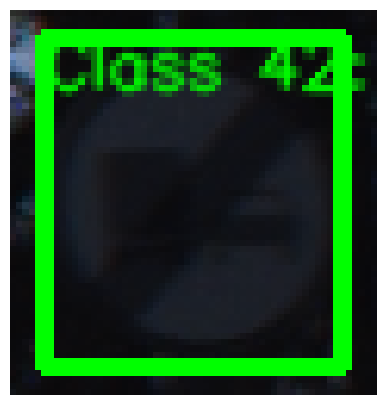

In [49]:
import matplotlib.pyplot as plt
from pathlib import Path

images = sorted((YOLO_ROOT / "images" / "val").glob("*.png"))

print("Total validation images:", len(images))

indices = [0, len(images)//4, len(images)//2,
           3*len(images)//4, len(images)-1]

for i in indices:
    print("\nTesting:", images[i].name)

    result = detect_and_classify(images[i])

    plt.figure(figsize=(5, 5))
    plt.imshow(result)
    plt.axis("off")
    plt.show()

In [50]:
from pathlib import Path

label_folder = YOLO_ROOT / "labels" / "val"
print("Label folder exists:", label_folder.exists())

for name in [
    "val_003915.png",
    "val_005872.png",
    "val_007829.png"
]:
    label_path = label_folder / name.replace(".png", ".txt")

    print("\nImage:", name)

    if label_path.exists():
        print("YOLO label:", label_path.read_text())
    else:
        print("No label file found")

Label folder exists: True

Image: val_003915.png
YOLO label: 12 0.500000 0.500000 0.773585 0.814815


Image: val_005872.png
YOLO label: 25 0.500000 0.508475 0.836066 0.813559


Image: val_007829.png
YOLO label: 42 0.500000 0.500000 0.830508 0.838710



In [51]:
import matplotlib.pyplot as plt
from pathlib import Path

save_folder = Path("/content/integration_results")
save_folder.mkdir(exist_ok=True)
images = sorted((YOLO_ROOT / "images" / "val").glob("*.png"))

indices = [
    0,
    len(images)//4,
    len(images)//2,
    3*len(images)//4,
    len(images)-1
]

for i, index in enumerate(indices, start=1):
    result = detect_and_classify(images[index])

    plt.imsave(
        save_folder / f"integration_example_{i}.png",
        result
    )

print("Saved 5 integration examples!")
print("Location:", save_folder)

Predicted class: 20
CNN confidence: 85.37%
Predicted class: 5
CNN confidence: 99.95%
Predicted class: 12
CNN confidence: 100.00%
Predicted class: 25
CNN confidence: 75.94%
Predicted class: 42
CNN confidence: 83.23%
Saved 5 integration examples!
Location: /content/integration_results


In [52]:
from pathlib import Path
images = sorted((YOLO_ROOT / "images" / "val").glob("*.png"))
labels = YOLO_ROOT / "labels" / "val"

indices = [
    0,
    len(images)//4,
    len(images)//2,
    3*len(images)//4,
    len(images)-1
]

for i in indices:
    image = images[i]
    label_file = labels / f"{image.stem}.txt"

    if label_file.exists():
        actual = label_file.read_text().split()[0]
        print(image.name, "Actual class:", actual)
    else:
        print(image.name, "Label missing")

val_000000.png Actual class: 20
val_001957.png Actual class: 5
val_003915.png Actual class: 12
val_005872.png Actual class: 25
val_007829.png Actual class: 42


In [53]:
import shutil
from pathlib import Path

source = Path("/content/integration_results")
destination = Path(
    "/content/drive/MyDrive/ARTI502_Project/"
    "results/integration_results"
)

destination.mkdir(parents=True, exist_ok=True)

for image in source.glob("*.png"):
    shutil.copy2(image, destination / image.name)

print("Saved to Google Drive!")
print("Number of images:", len(list(destination.glob("*.png"))))

Saved to Google Drive!
Number of images: 5


In [54]:
print("YOLO class mapping:")
print(detector.names)

print("\nCNN output classes:")
print(cnn.output_shape[-1])

YOLO class mapping:
{0: 'Traffic Sign 0', 1: 'Traffic Sign 1', 2: 'Traffic Sign 2', 3: 'Traffic Sign 3', 4: 'Traffic Sign 4', 5: 'Traffic Sign 5', 6: 'Traffic Sign 6', 7: 'Traffic Sign 7', 8: 'Traffic Sign 8', 9: 'Traffic Sign 9', 10: 'Traffic Sign 10', 11: 'Traffic Sign 11', 12: 'Traffic Sign 12', 13: 'Traffic Sign 13', 14: 'Traffic Sign 14', 15: 'Traffic Sign 15', 16: 'Traffic Sign 16', 17: 'Traffic Sign 17', 18: 'Traffic Sign 18', 19: 'Traffic Sign 19', 20: 'Traffic Sign 20', 21: 'Traffic Sign 21', 22: 'Traffic Sign 22', 23: 'Traffic Sign 23', 24: 'Traffic Sign 24', 25: 'Traffic Sign 25', 26: 'Traffic Sign 26', 27: 'Traffic Sign 27', 28: 'Traffic Sign 28', 29: 'Traffic Sign 29', 30: 'Traffic Sign 30', 31: 'Traffic Sign 31', 32: 'Traffic Sign 32', 33: 'Traffic Sign 33', 34: 'Traffic Sign 34', 35: 'Traffic Sign 35', 36: 'Traffic Sign 36', 37: 'Traffic Sign 37', 38: 'Traffic Sign 38', 39: 'Traffic Sign 39', 40: 'Traffic Sign 40', 41: 'Traffic Sign 41', 42: 'Traffic Sign 42'}

CNN outpu

In [55]:
print("YOLO classes:", len(detector.names))
print("CNN classes:", cnn.output_shape[-1])

print("YOLO class IDs:", sorted(detector.names.keys()))

YOLO classes: 43
CNN classes: 43
YOLO class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]
